# 02 — Exploratory Data Analysis (EDA)
**Event Recommendation System** · Stage 3

Understand how users behave before choosing models. Every chart ends with a **takeaway** and the **modelling decision** it leads to.

### Setup (run this first)
- **In Google Colab** this cell downloads the project from GitHub (data + `src/` code) and moves into it.
- **On your own computer** it just moves from `notebooks/` to the project root.

`sys.path.insert(0, "src")` lets us `import recsys` - the small package that holds the reusable code (cleaning, models, metrics). Notebooks *explain* the code; `src/recsys` *stores* it so every notebook uses exactly the same implementation.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/Abdelrahman2115/recommender-system.git"

if "google.colab" in sys.modules:                       # running inside Google Colab
    if not os.path.exists("/content/recommender-system"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/recommender-system"], check=True)
    os.chdir("/content/recommender-system")
elif os.path.basename(os.getcwd()) == "notebooks":      # running locally from the notebooks folder
    os.chdir("..")

sys.path.insert(0, "src")                               # make `import recsys` work
print("Project root:", os.getcwd())

Project root: /home/claude/recommender-system


## 0. Load the cleaned data
EDA on dirty data gives misleading charts (e.g. `cairo` and `Cairo` counted as two cities), so we use the cleaning functions from `src/recsys/data.py`. They are explained line by line in notebook 03 — here we only need clean tables.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recsys.data import load_clean, POSITIVE_TYPES
from recsys.plotting import set_style, bar_labels, MAIN, TEXT

set_style()                                  # one consistent chart style for the whole project
users, events, inter = load_clean()

# One wide table: every interaction + the user's and the event's attributes.
df = (inter.merge(users[["user_id", "age", "city", "interests"]], on="user_id")
           .merge(events[["event_id", "category", "city", "price", "venue_type", "start_datetime"]],
                  on="event_id", suffixes=("_user", "_event")))
df["positive"] = df["interaction_type"].isin(POSITIVE_TYPES)   # going or attended = success
print(df.shape)

(50018, 15)


## 1. The engagement funnel
Each interaction is one of four steps: **view → interested → going → attended**. The order of the bars follows the funnel, not the counts.

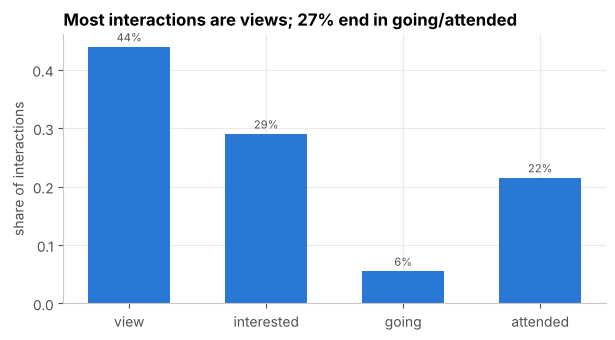

In [3]:
order = ["view", "interested", "going", "attended"]
share = df["interaction_type"].value_counts(normalize=True).reindex(order)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(order, share.values, color=MAIN, width=0.6)
bar_labels(ax, fmt="{:.0%}")
ax.set_ylabel("share of interactions")
ax.set_title("Most interactions are views; 27% end in going/attended")
plt.show()

**Takeaway:** views are the most common action, and only about a quarter of interactions are "going" or "attended". This mirrors real funnels where many people browse and few commit.

**Decision:** for ranking, a **relevant** event = one the user marked *going* or *attended* (a real commitment, not a casual view). We still use views and "interested" as weaker training signals.

## 2. Ratings

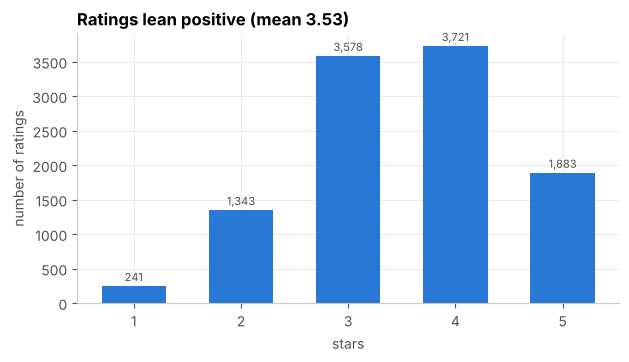

ratings per user (median): 4.0
spread of users' average rating (std): 0.66


In [4]:
ratings = df["rating"].dropna()
counts = ratings.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(counts.index.astype(int).astype(str), counts.values, color=MAIN, width=0.6)
bar_labels(ax, fmt="{:,.0f}")
ax.set_xlabel("stars"); ax.set_ylabel("number of ratings")
ax.set_title(f"Ratings lean positive (mean {ratings.mean():.2f})")
plt.show()

per_user = df.dropna(subset=["rating"]).groupby("user_id")["rating"]
print("ratings per user (median):", per_user.size().median())
print("spread of users' average rating (std):", round(per_user.mean().std(), 2))

**Takeaway:** ratings are skewed toward 3–4 stars — people mostly attend events they expected to like. The median user has only **4 ratings**, but users differ in their average rating (std ≈ 0.66 stars): some rate generously, some harshly.

**Decision:** model a **user bias** (b_u) and an **event bias** (b_e) — this is exactly what the SVD model's bias terms do. Also: always compare against the **global-mean baseline**; with ratings this concentrated, it is hard to beat.

## 3. Long tails: activity per user and popularity per event

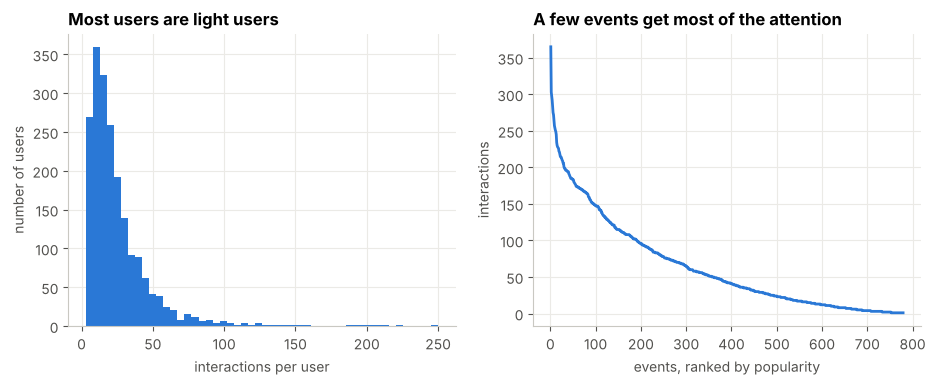

median interactions per user: 18  (max 250)
top 20% of events receive 53% of all interactions
events with no interactions at all: 21


In [5]:
per_user = df.groupby("user_id").size()
per_event = df.groupby("event_id").size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(per_user, bins=50, color=MAIN)
axes[0].set_xlabel("interactions per user"); axes[0].set_ylabel("number of users")
axes[0].set_title("Most users are light users")

axes[1].plot(np.arange(1, len(per_event) + 1), per_event.values, color=MAIN, linewidth=2)
axes[1].set_xlabel("events, ranked by popularity"); axes[1].set_ylabel("interactions")
axes[1].set_title("A few events get most of the attention")
plt.show()

top20 = per_event.head(int(0.2 * len(per_event))).sum() / per_event.sum()
print(f"median interactions per user: {per_user.median():.0f}  (max {per_user.max()})")
print(f"top 20% of events receive {top20:.0%} of all interactions")
print(f"events with no interactions at all: {events['event_id'].nunique() - per_event.size}")

**Takeaway:** both distributions are **long-tailed**. The median user has 18 interactions, a few have 200+. The top 20% of events receive more than half of all interactions.

**Decision:** a **popularity baseline** will be reasonably strong, so every model must beat it to be worth using. Light users and unpopular events are where personalisation matters most.

## 4. Sparsity
If we draw a table with users as rows and events as columns, how much of it is filled?

In [6]:
n_users, n_events = users["user_id"].nunique(), events["event_id"].nunique()
sparsity = 1 - len(inter) / (n_users * n_events)
print(f"{n_users} users x {n_events} events = {n_users * n_events:,} possible pairs")
print(f"observed interactions: {len(inter):,}  ->  sparsity = {sparsity:.1%}")

2000 users x 800 events = 1,600,000 possible pairs
observed interactions: 50,018  ->  sparsity = 96.9%


**Takeaway:** about **97% of the user–event table is empty**. This is normal for recommender systems (Netflix's rating matrix is ~99% empty).

**Decision:** store the matrix as a **sparse matrix** (only non-zero values), and use **matrix factorisation (SVD)**, which is designed to fill in missing values from a few observed ones.

## 5. Location: do people attend events in their own city?

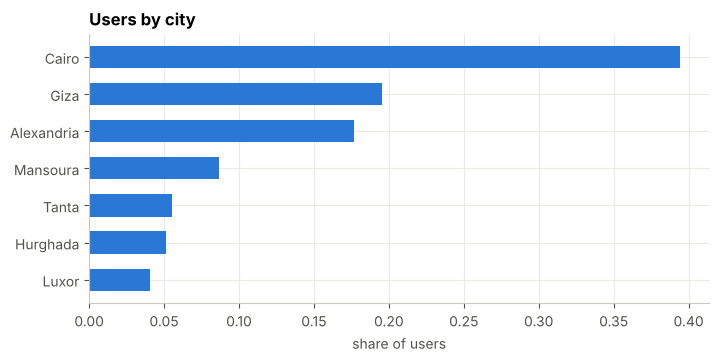

in-person going/attended events in the user's own city: 53%  (chance level: 25%)
all interactions (incl. views) in the user's own city:   39%
share of going/attended that are online events:          20%


In [7]:
pos = df[df["positive"]]
in_person = pos[pos["venue_type"] != "online"]
same_city = (in_person["city_user"] == in_person["city_event"]).mean()
baseline = (df["city_user"] == df["city_event"]).mean()
# chance level: if city did not matter, the share would equal how common the user's city is among events
city_share_events = events.loc[events["venue_type"] != "online", "city"].value_counts(normalize=True)
chance = in_person["city_user"].map(city_share_events).mean()

share_users = users["city"].value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(share_users.index[::-1], share_users.values[::-1], color=MAIN, height=0.6)
ax.set_xlabel("share of users"); ax.set_title("Users by city")
plt.show()

print(f"in-person going/attended events in the user's own city: {same_city:.0%}  (chance level: {chance:.0%})")
print(f"all interactions (incl. views) in the user's own city:   {baseline:.0%}")
print(f"share of going/attended that are online events:          {(pos['venue_type'] == 'online').mean():.0%}")

**Takeaway:** about half of in-person commitments are in the user's **home city** — roughly double the chance level. Users browse events in other cities (only 39% of all interactions are local) but commit locally. Online events (20% of commitments) remove the distance barrier.

**Decision:** **city is a feature** of each event vector, and the user's home city is part of their profile (this especially helps brand-new users).

## 6. Do stated interests predict behaviour?

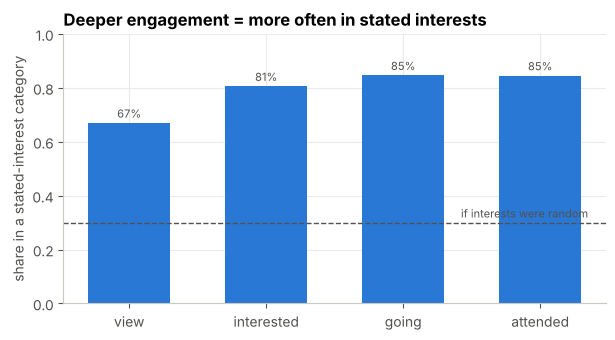

In [8]:
df["in_interests"] = [c in s.split("|") for c, s in zip(df["category"], df["interests"])]
by_type = df.groupby("interaction_type")["in_interests"].mean().reindex(order)
random_share = users["interests"].str.split("|").str.len().mean() / events["category"].nunique()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(order, by_type.values, color=MAIN, width=0.6)
ax.axhline(random_share, color=TEXT, linestyle="--", linewidth=1)
ax.text(3.35, random_share + 0.02, "if interests were random", ha="right", fontsize=8, color=TEXT)
bar_labels(ax, fmt="{:.0%}")
ax.set_ylim(0, 1); ax.set_ylabel("share in a stated-interest category")
ax.set_title("Deeper engagement = more often in stated interests")
plt.show()

**Takeaway:** about 85% of *going/attended* events belong to a category the user selected at sign-up, versus ~30% if interests meant nothing. But not 100% — people list interests they never act on and attend things outside their list.

**Decision:** stated interests are a strong starting profile for **new users** (cold start), but **behaviour should take over** as history grows. Our content-based profile blends the two, weighting history more as it accumulates.

## 7. Category and price

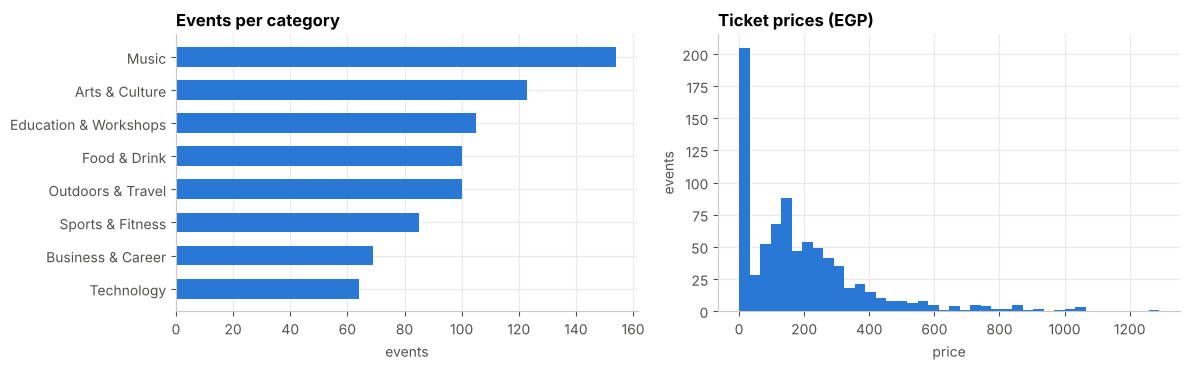

free
free    31.6%
paid    24.3%
Name: going/attended rate, dtype: str


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cat_counts = events["category"].value_counts()
axes[0].barh(cat_counts.index[::-1], cat_counts.values[::-1], color=MAIN, height=0.6)
axes[0].set_title("Events per category"); axes[0].set_xlabel("events")

axes[1].hist(events["price"], bins=40, color=MAIN)
axes[1].set_title("Ticket prices (EGP)"); axes[1].set_xlabel("price"); axes[1].set_ylabel("events")
plt.tight_layout(); plt.show()

df["free"] = np.where(df["price"] == 0, "free", "paid")
print(df.groupby("free")["positive"].mean().map("{:.1%}".format).rename("going/attended rate"))

**Takeaway:** categories are unevenly represented (Music has the most events, Technology the fewest). Prices are right-skewed: a quarter of events are free, and a few cost over 1,000 EGP. Free events convert better (higher going/attended rate).

**Decision:** use **price buckets** (free / cheap / medium / expensive) as a feature rather than the raw price — an event at 150 EGP and one at 160 EGP should look the same to the model.

## 8. Time: the platform grows, and events are short-lived

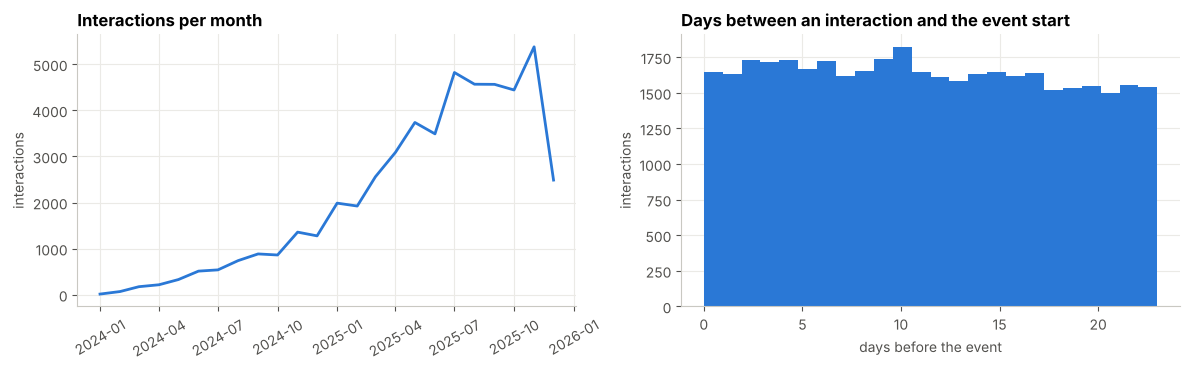

views/interest/going happen at most 23 days before the event (median 11)


In [10]:
monthly = inter.set_index("timestamp").resample("MS").size()
lead_days = (df["start_datetime"] - df["timestamp"]).dt.days
before = lead_days[df["interaction_type"] != "attended"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(monthly.index, monthly.values, color=MAIN, linewidth=2)
axes[0].set_title("Interactions per month"); axes[0].set_ylabel("interactions")
axes[0].tick_params(axis="x", rotation=30)

axes[1].hist(before, bins=24, color=MAIN)
axes[1].set_title("Days between an interaction and the event start")
axes[1].set_xlabel("days before the event"); axes[1].set_ylabel("interactions")
plt.tight_layout(); plt.show()
print(f"views/interest/going happen at most {before.max()} days before the event (median {before.median():.0f})")

**Takeaway:** the platform grows over time (the dip in the final month is an edge effect: the data ends on 31 Dec 2025, so events in early 2026 and their interactions are not included). Interactions with an event spread evenly over the ~3 weeks before it starts, and none happen earlier — every event has a short life.

**Decisions — the most important of the EDA:**
1. **Split by time, globally** — train on the past, test on the future. A random split would let the model learn from future behaviour (data leakage).
2. **Item cold start is the normal case**: when we recommend next month's events, most of them have little or no history yet. Collaborative filtering alone cannot rank those, so we need content features — this is the core justification for a **hybrid**.

## 9. Does age matter?

In [11]:
df["age_band"] = pd.cut(df["age"], [0, 20, 25, 30, 35, 100], labels=["≤20", "21-25", "26-30", "31-35", "36+"])
age_table = df.groupby("age_band", observed=True).agg(
    users=("user_id", "nunique"),
    going_attended_rate=("positive", "mean"),
    avg_rating=("rating", "mean"),
).round(3)
age_table

,users,going_attended_rate,avg_rating
age_band,,,
≤20,359,0.274,3.492
21-25,505,0.272,3.521
26-30,602,0.265,3.549
31-35,326,0.272,3.549
36+,208,0.274,3.499


**Takeaway:** engagement and ratings are almost identical across age bands.

**Decision:** **do not use age** as a model feature — it adds complexity without signal. (Good EDA also tells you what to leave out.)

## Summary: from EDA to design

| Finding | Design decision |
|---|---|
| 27% of interactions are going/attended | "Relevant" = going/attended in ranking metrics |
| Ratings concentrated at 3–4; users have rating habits | SVD with user/event biases; global-mean baseline |
| Long-tailed popularity | Popularity baseline that all models must beat |
| 97% sparse | Sparse matrices + matrix factorisation (SVD) |
| Attendance is local | City in event vectors and user profiles |
| Interests predict ~85% of commitments | Interests seed the profile; history takes over |
| Events live ~3 weeks | Global time split; content needed for new events → **hybrid** |
| Age has no signal | Age not used |

### Interview questions for this stage
- *What is the long tail and why does it matter?* — Most items get few interactions. A recommender that only learns popularity never surfaces niche items that individual users would love.
- *What is sparsity?* — The share of the user–item matrix with no data. High sparsity makes it hard to find similar users, which is why we compress users and items into a few latent factors.
- *Why didn't you use age?* — EDA showed no relationship between age and engagement or ratings, so it would only add noise.

**Next:** `03_cleaning_and_split.ipynb`.